loading libraries

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = [16, 7]

loading images

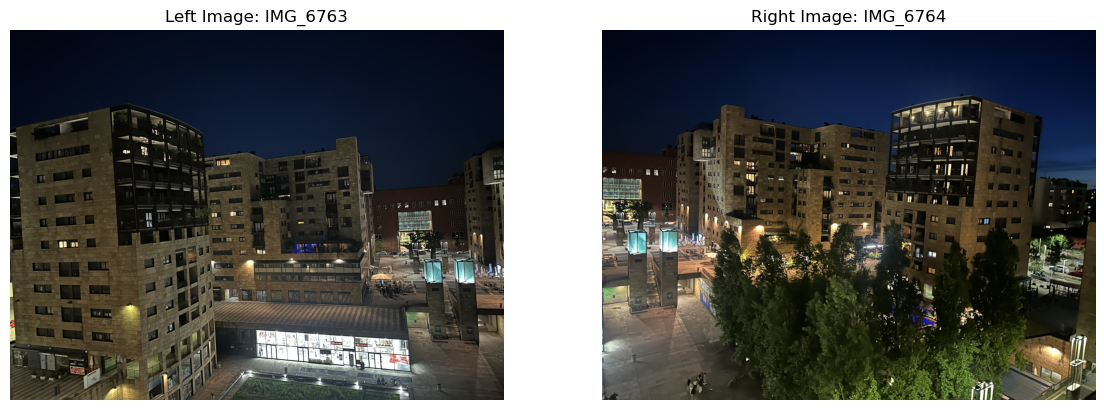

In [3]:
left_path = "C:\\Users\\Admin\\Downloads\\IMG_7048.jpeg"
right_path = "C:\\Users\\Admin\\Downloads\\IMG_7049.jpeg"

left_bgr = cv.imread(left_path)
right_bgr = cv.imread(right_path)

if left_bgr is None:
    raise FileNotFoundError("Left image not found. Check the filename.")

if right_bgr is None:
    raise FileNotFoundError("Right image not found. Check the filename.")

left = cv.cvtColor(left_bgr, cv.COLOR_BGR2RGB)
right = cv.cvtColor(right_bgr, cv.COLOR_BGR2RGB)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(left)
plt.title("Left Image: IMG_6763")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(right)
plt.title("Right Image: IMG_6764")
plt.axis("off")

plt.show()

resizing the images

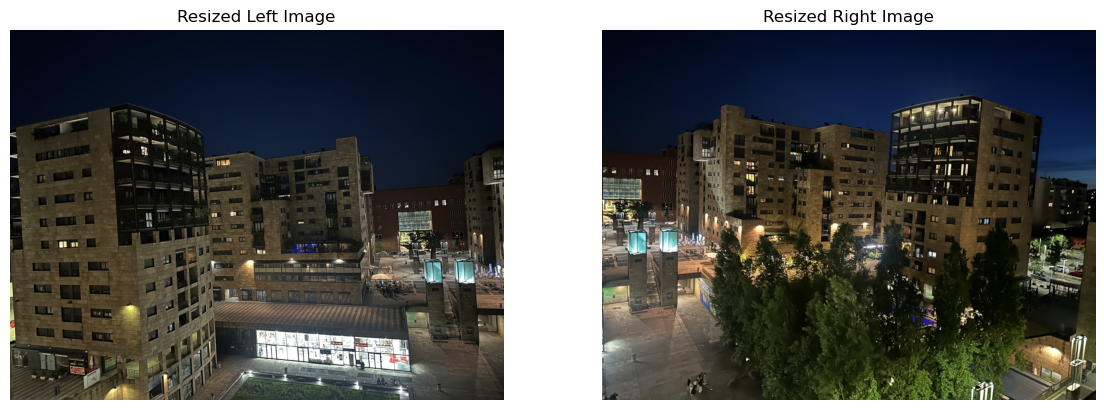

In [4]:
def resize_image(image, width=900):
    h, w = image.shape[:2]
    scale = width / w
    new_height = int(h * scale)
    resized = cv.resize(image, (width, new_height), interpolation=cv.INTER_AREA)
    return resized

left = resize_image(left, width=900)
right = resize_image(right, width=900)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(left)
plt.title("Resized Left Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(right)
plt.title("Resized Right Image")
plt.axis("off")

plt.show()

converting to gray

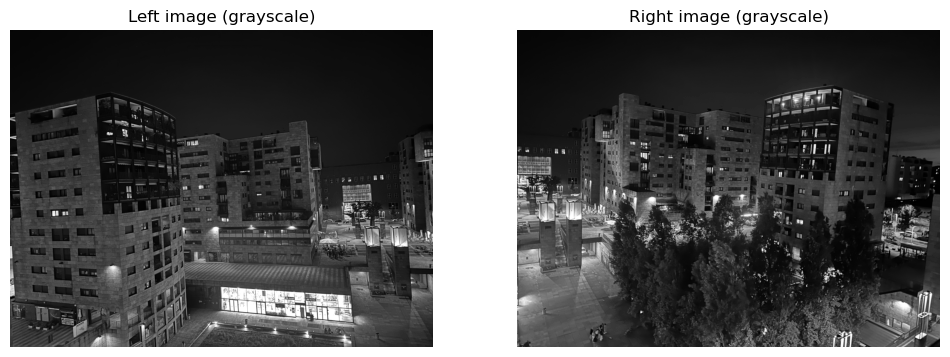

In [5]:
gray_left = cv.cvtColor(left, cv.COLOR_RGB2GRAY)
gray_right = cv.cvtColor(right, cv.COLOR_RGB2GRAY)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray_left, cmap='gray')
plt.title("Left image (grayscale)")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(gray_right, cmap='gray') 
plt.title("Right image (grayscale)")
plt.axis("off")
plt.show()

Extract local features and descriptors using SIFT.

In [6]:
# Keypoints extraction
sift = cv.SIFT_create()
im1 = gray_left
im2 = gray_right
kps1, features1 = sift.detectAndCompute(im1, None)
kps2, features2 = sift.detectAndCompute(im2, None)



Match descriptors between the two images using KNN.

In [7]:
bf = cv.BFMatcher(cv.NORM_L2, crossCheck=False)
matches = bf.knnMatch(features1, features2, k=2)

Filter unreliable matches using Lowe's ratio test.

In [8]:
# Take the top 50 matches
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

Ensure sufficient correspondences for homography estimation.

In [9]:
# Require at least 4 matches to compute homography
if len(good_matches) < 4:
    raise Exception("Not enough matches found to compute homography")

Estimate a robust homography using RANSAC.

In [10]:
def myHomography(kps1, kps2, matches):

    # Extract matched keypoint coordinates
    src_pts = np.float32([kps1[m.queryIdx].pt for m in matches]).reshape(-1,1,2)
    dst_pts = np.float32([kps2[m.trainIdx].pt for m in matches]).reshape(-1,1,2)

    # Use RANSAC to be robust to outliers
    H, mask = cv.findHomography(dst_pts, src_pts, cv.RANSAC, 5.0)

    return H

Compute the geometric transformation between images.

In [11]:
H = myHomography(kps1, kps2, good_matches)
print("Computed Homography Matrix:", H)

Computed Homography Matrix: [[-1.83816399e-03 -4.58914908e-03  6.87872242e+02]
 [-4.37883709e-01  8.27916279e-01  1.00437470e+02]
 [-1.08398399e-03 -9.91536885e-05  1.00000000e+00]]


Retrieve image dimensions for panorama creation.

In [12]:
h1, w1 = im1.shape[:2]

Apply perspective warping to align the second image.

In [13]:
def myWarp(im, H):
    h2, w2 = im.shape[:2] 
    warped_im2 = cv.warpPerspective(im, H, (w1 + w2, max(h1, h2)))
    return warped_im2

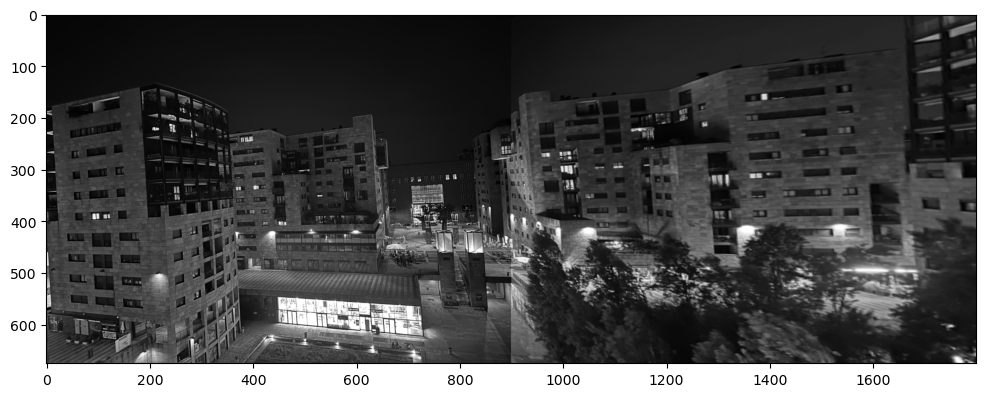

In [14]:
# Warp image 2 to image 1's plane
temp = myWarp(im2, H)
temp[0:h1, 0:w1] = im1

plt.figure(figsize=(12, 24))
plt.imshow(temp, cmap='gray')
plt.show()